# Generate app data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from slabguide import Slab, Propagator, real_contour, ThreeJSMeshSaver

plt.style.use('dark_background')

In [23]:
A = Slab(scale=1e-5, Ts=[6.5, 1, 6, 1, 6.5],  ns=[1, 1.44, 1, 1.44, 1],
                 xrefs=[325, 200, 300, 200, 325], wl=5.83e-06)

B = Slab(scale=1e-5, Ts=[6.5, 1, 6, 1, 6.5],  ns=[1, 1.44, 1, 1.44, 1],
                 xrefs=[325, 200, 300, 200, 325], wl=6.90764471839393e-06)

In [3]:
half_width = 1
shift = .5
amplitude = 1

Lx = -half_width + shift
Rx = half_width + shift

def quadratic_piecewise(x):
    x = np.array(x, dtype=float)
    conds = [(x < Lx), ((Lx <= x)*(x <= Rx)), (x > Rx)]
    funcs = [lambda x: 0, lambda x: amplitude * (1 - ((x - shift) / half_width)**2), lambda x: 0]
    return np.piecewise(x, conds, funcs)

f0 = quadratic_piecewise

In [4]:
P = Propagator(A, f0=f0, window=[Lx, Rx], calculate_guided_field=False)

In [5]:
Np = 100
Lz = .001
Rz = 1
P.add_contour(real_contour(Lz, Rz, Np))

In [6]:
Np = 500
Lz = 1
Rz = A.Z_evanescent

P.add_contour(real_contour(Lz, Rz, Np))

In [7]:
P.add_contour(real_contour(.515, .525, 80))
P.add_contour(real_contour(1.02, 1.06, 40))
P.add_contour(real_contour(1.53, 1.58, 40))
P.add_contour(real_contour(2.05, 2.1, 40))

In [8]:
Np = 100
Lz = A.Z_evanescent
Rz = 30

P.add_contour(real_contour(Lz, Rz, Np))

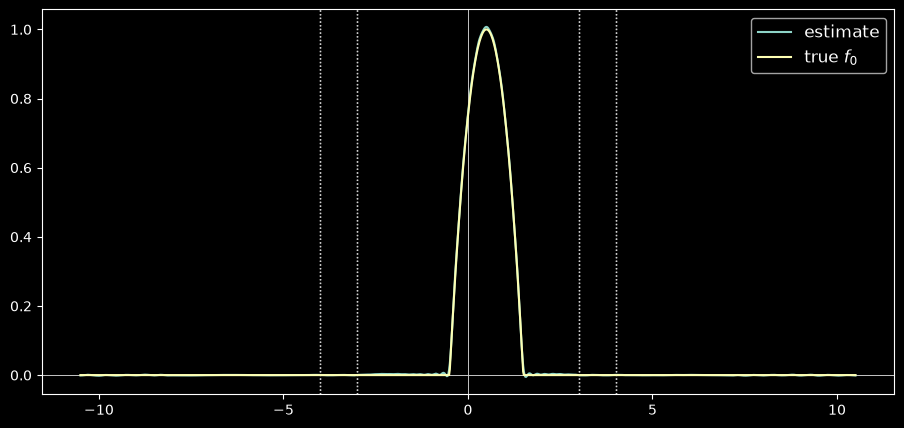

In [24]:
A.plot_field_1d(P, label='estimate') 
A.add_1d_plot(f0, label='true $f_0$');
plt.show();

In [10]:
Q = Propagator(B, f0=f0, window=[Lx, Rx], calculate_guided_field=False)

In [11]:
Lz = .001
Rz = B.Z_evanescent
Np = 800

Q.add_contour(real_contour(Lz, Rz, Np))

In [12]:
Lz = B.Z_evanescent
Rz = 30
Np = 200

Q.add_contour(real_contour(Lz, Rz, Np))

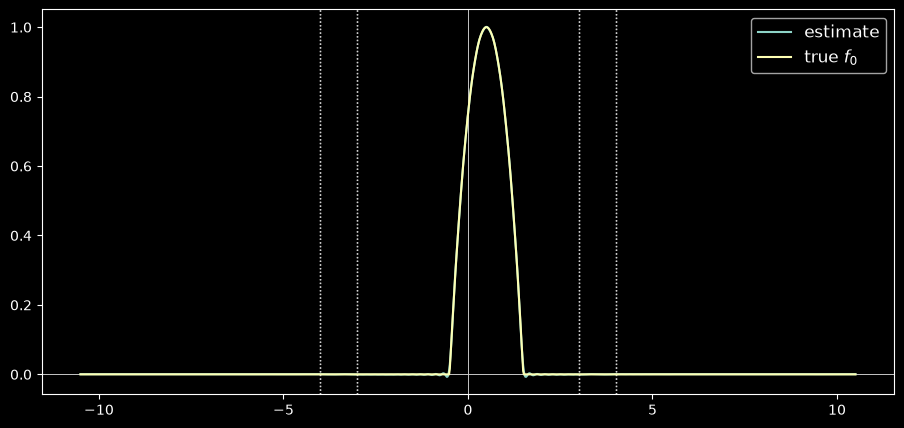

In [25]:
B.plot_field_1d(Q, label='estimate') 
B.add_1d_plot(f0, label='true $f_0$');
plt.show();

In [26]:
xs = A.all_Xs[::8]
ys = np.linspace(0, 50, int(50*30))
ymin, ymax = np.min(ys), np.max(ys)

Xs, Ys = np.meshgrid(xs, ys)
MS = ThreeJSMeshSaver(Xs, Ys)

trigs = MS.trig_indices
basepts = MS.base_vertices

Props = [P, Q]

gs = np.array([Prop.Guided(xs,ys) for Prop in Props])
ps = np.array([Prop.Propagating(xs, ys) for Prop in Props])
evs = np.array([Prop.Evanescent(xs, ys) for Prop in Props])
f0s = np.array(Props[0].f0(xs), dtype=np.float32)
Nmesh = np.array(len(Props), dtype=np.uint32)

Rhos = A.Rhos

In [15]:
ps.shape

(2, 1500, 122)

In [16]:
MS.create_height_array_multi_mesh_complex(ps).shape

(2, 366000)

In [27]:
prefix='/home/pv/local/website/visualizations/hollow_core/data/'

In [28]:
MS.save_trig_indices_as_json(prefix + 'trig_indices')
MS.save_base_vertices_as_json(prefix + 'base_vertices')


In [29]:
MS.save_values_as_json(prefix + 'f0s', f0s)
MS.save_values_as_json(prefix + 'x0s', xs)
MS.save_values_as_json(prefix + 'y0s', ys)
MS.save_values_as_json(prefix + 'Rhos', Rhos)


In [30]:
MS.save_heights_as_json_not_flat_complex(prefix + 'guided', gs, reduce_dims=False)


In [31]:
MS.save_heights_as_json_not_flat_complex(prefix + 'propagating', ps, reduce_dims=False)


In [32]:
MS.save_heights_as_json_not_flat_complex(prefix + 'evanescent', evs, reduce_dims=False)
